# TexTag: Would more data help? (learning curve)

If we paid for more labeled textures, how much better would the search model get?

**Method:** train the same model on slices of the training data (5, 10, 20 and 40 images per class) and plot the
test score against the number of training images. This is a **learning curve**:

- still climbing at 100% → more data should help
- flat → more data won't help much; spend on something else (better labels, a better model)

A line fitted through the points gives a rough estimate of the gain from 2×, 5× or 50× more images,
which we can put next to the cost of labeling them.

**Model:** the multi-label ResNet18 from `07_search` (same two phases, settings and early stopping).
**Scores:** test mAP and tag-search precision@10, as in `07_search`.

**Run on Google Colab:** Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all (~25 min).

Sections:
1. Setup
2. Data slices
3. Training function
4. Train on each slice
5. Learning curve
6. Extrapolation
7. Cost vs benefit
8. Findings

## 1. Setup

In [1]:
import os, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("/content/textag"):
        !git clone -q https://github.com/codecustard/textag.git /content/textag
    %cd /content/textag/notebooks

/content/textag/notebooks


In [2]:
from pathlib import Path
from timeit import default_timer as timer

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import average_precision_score

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from textag.model import resnet18, unfreeze
from textag import multilabel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

EPOCHS = os.environ.get("TEXTAG_EPOCHS")   # env var only used for quick test runs

device: cuda


## 2. Data slices

Same images and labels as `07_search`. Validation and test stay the same full sets (1,880 images each);
only the **training** set shrinks.

Each slice takes the **same number of images from every class** (by the image's main class), so all 47 classes
are always there and only the amount changes. The slices are **nested**: the 10-per-class slice contains the
5-per-class slice, and so on. So each step only *adds* data.

In [3]:
dl = multilabel.loaders(batch_size=32, num_workers=2)
train_ds = dl["train"].dataset
classes = train_ds.classes
test_targets = dl["test"].dataset.targets

main_class = train_ds.dtd._labels          # each training image's main class (0-46), from the single-label data

def slice_indices(per_class):
    """The first `per_class` training images of every class."""
    indices = []
    for c in range(len(classes)):
        in_class = [i for i, label in enumerate(main_class) if label == c]
        indices += in_class[:per_class]
    return indices

SLICES = [5, 10, 20, 40]                   # images per class; 40 = the full training set
for per_class in SLICES:
    n = len(slice_indices(per_class))
    print(f"{per_class:>2} per class -> {n:>4} training images ({n / len(train_ds):.1%})")

# nested: every smaller slice is inside the bigger ones
assert set(slice_indices(5)) <= set(slice_indices(10)) <= set(slice_indices(20)) <= set(slice_indices(40))

100%|██████████| 625M/625M [00:43<00:00, 14.4MB/s]


 5 per class ->  235 training images (12.5%)
10 per class ->  470 training images (25.0%)
20 per class ->  940 training images (50.0%)
40 per class -> 1880 training images (100.0%)


## 3. Training function

Exactly the `07_search` recipe, wrapped in a function so it can run once per slice:

| | Phase 1: feature extractor | Phase 2: fine-tuning |
|---|---|---|
| What trains | Only the new last layer | All layers |
| Learning rate | 1e-3, up to 15 epochs | 1e-4, up to 20 epochs |
| Early stopping | patience 5 (on the full validation set) | patience 5 |

Loss `BCEWithLogitsLoss`, optimizer `AdamW` (weight decay 1e-4), `ReduceLROnPlateau`. After training,
the model scores the **test** set: mAP (all 47 tags, whole ranking) and tag-search precision@10.

In [4]:
def train_and_score(per_class):
    """Train the multi-label ResNet18 on one slice; return its test scores."""
    torch.manual_seed(42)                      # same starting point for every slice
    indices = slice_indices(per_class)
    train_dataloader = DataLoader(Subset(train_ds, indices), batch_size=32, shuffle=True, num_workers=2)

    model = resnet18(num_classes=len(classes), pretrained=True, freeze_backbone=True)
    loss_fn = torch.nn.BCEWithLogitsLoss()
    start = timer()

    # Phase 1: only the new last layer
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=3)
    hist1 = multilabel.train(model, train_dataloader, dl["val"], optimizer, loss_fn,
                             epochs=int(EPOCHS or 15), device=device, scheduler=scheduler, patience=5, verbose=False)

    # Phase 2: all layers, 10x smaller learning rate
    unfreeze(model)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=3)
    hist2 = multilabel.train(model, train_dataloader, dl["val"], optimizer, loss_fn,
                             epochs=int(EPOCHS or 20), device=device, scheduler=scheduler, patience=5, verbose=False)
    seconds = timer() - start

    # Score the test set
    tag_scores, _ = multilabel.index(model, dl["test"], device)
    return {"per class": per_class,
            "training images": len(indices),
            "test mAP": average_precision_score(test_targets, tag_scores, average="macro"),
            "tag search P@10": multilabel.tag_search_precision(tag_scores, test_targets).mean().item(),
            "epochs (phase 1 + 2)": f"{len(hist1['val_loss'])} + {len(hist2['val_loss'])}",
            "training time (s)": round(seconds)}

## 4. Train on each slice

Four full trainings, smallest first (~25 min on a T4 in total).

In [5]:
rows = []
for per_class in SLICES:
    row = train_and_score(per_class)
    rows.append(row)
    print(f"{row['training images']:>4} images: test mAP {row['test mAP']:.1%}, "
          f"tag search P@10 {row['tag search P@10']:.1%}  ({row['training time (s)']} s)")

curve = pd.DataFrame(rows).set_index("training images")
curve.style.format({"test mAP": "{:.1%}", "tag search P@10": "{:.1%}"})

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 65.5MB/s]


 235 images: test mAP 44.7%, tag search P@10 69.4%  (388 s)
 470 images: test mAP 53.8%, tag search P@10 80.0%  (380 s)
 940 images: test mAP 58.8%, tag search P@10 83.4%  (407 s)
1880 images: test mAP 69.7%, tag search P@10 91.7%  (642 s)


,per class,test mAP,tag search P@10,epochs (phase 1 + 2),training time (s)
training images,,,,,
235,5,44.7%,69.4%,15 + 18,388
470,10,53.8%,80.0%,15 + 14,380
940,20,58.8%,83.4%,15 + 10,407
1880,40,69.7%,91.7%,15 + 14,642


## 5. Learning curve

The x-axis is on a **log scale** (each step doubles the data). Learning curves usually look close to a straight
line on this scale, which is what makes the extrapolation in the next section possible.

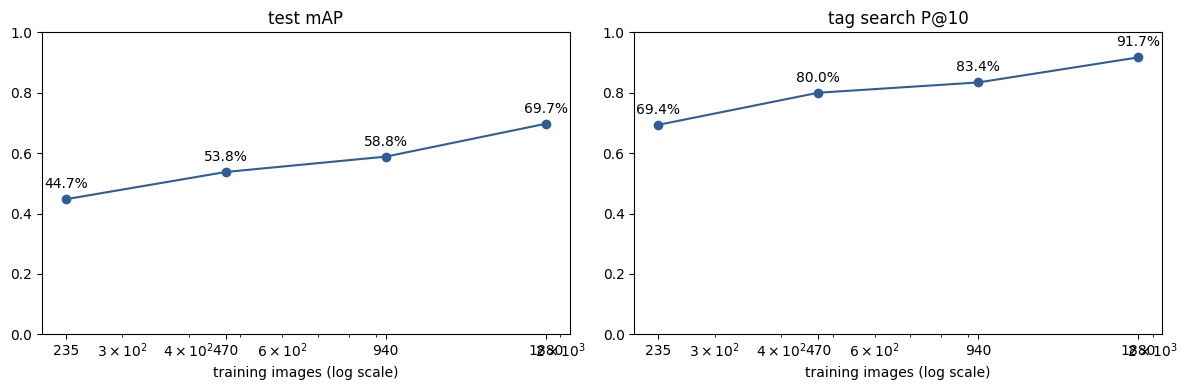

test mAP: gain per doubling = +9.0%, +5.1%, +10.9%
tag search P@10: gain per doubling = +10.6%, +3.4%, +8.3%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["test mAP", "tag search P@10"]):
    ax.plot(curve.index, curve[metric], "o-", color="#2F5E96")
    for n, value in curve[metric].items():
        ax.annotate(f"{value:.1%}", (n, value), textcoords="offset points", xytext=(0, 8), ha="center")
    ax.set_xscale("log")
    ax.set_xticks(curve.index, [str(n) for n in curve.index])
    ax.set_xlabel("training images (log scale)")
    ax.set_title(metric)
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

for metric in ["test mAP", "tag search P@10"]:
    gains = curve[metric].diff().dropna()
    print(f"{metric}: gain per doubling = " + ", ".join(f"{g:+.1%}" for g in gains))

## 6. Extrapolation

Fit a straight line through the points on the log scale: `score ≈ a + b × log10(images)`.
Then `b` is the gain from **10×** more images, and `b × log10(2)` the gain per **doubling**.

**This is a rough estimate.** The real curve usually bends and flattens with much more data (and can't pass 100%),
so the further we go past 1,880 images, the more optimistic the line becomes. Use it for the order of magnitude only.

In [7]:
FUTURE = [3_760, 10_000, 100_000]          # 2x DTD's training set, ~5x, ~50x

fits, predictions = {}, {}
for metric in ["test mAP", "tag search P@10"]:
    b, a = np.polyfit(np.log10(curve.index), curve[metric], 1)    # slope, intercept
    fits[metric] = (a, b)
    predictions[metric] = [min(a + b * np.log10(n), 1.0) for n in FUTURE]
    print(f"{metric}: score ≈ {a:.3f} + {b:.3f} × log10(images)  ->  +{b * np.log10(2):.1%} per doubling")

prediction_table = pd.DataFrame(predictions, index=pd.Index(FUTURE, name="training images (extrapolated)"))
prediction_table.style.format("{:.1%}")

test mAP: score ≈ -0.183 + 0.266 × log10(images)  ->  +8.0% per doubling
tag search P@10: score ≈ 0.151 + 0.234 × log10(images)  ->  +7.0% per doubling


,test mAP,tag search P@10
training images (extrapolated),,
3760,76.8%,98.7%
10000,88.1%,100.0%
100000,100.0%,100.0%


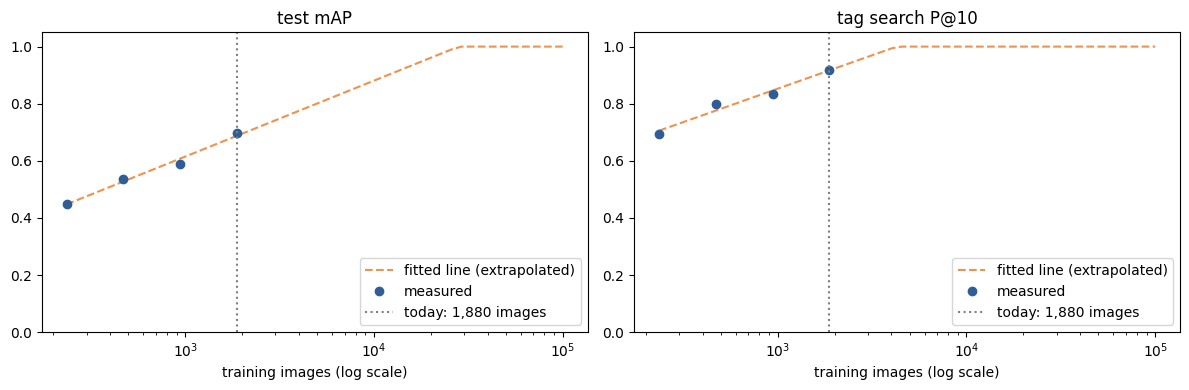

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
line_x = np.logspace(np.log10(curve.index.min()), np.log10(FUTURE[-1]), 50)
for ax, metric in zip(axes, ["test mAP", "tag search P@10"]):
    a, b = fits[metric]
    ax.plot(line_x, np.minimum(a + b * np.log10(line_x), 1.0), "--", color="#F0924F", label="fitted line (extrapolated)")
    ax.plot(curve.index, curve[metric], "o", color="#2F5E96", label="measured")
    ax.axvline(curve.index.max(), color="gray", linestyle=":", label="today: 1,880 images")
    ax.set_xscale("log")
    ax.set_xlabel("training images (log scale)")
    ax.set_title(metric)
    ax.set_ylim(0, 1.05)
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### A more realistic curve: power law

The straight line above keeps climbing until it hits 100%, which real learning curves don't do: each extra image helps a bit
less than the one before (*diminishing returns*). The usual model is a **power law**: the **error** (100% − score) shrinks by
the same factor with every doubling of data,

`error ≈ c × images^k` (k is negative)

On a log-log scale that's a straight line, so it's the same `np.polyfit` as above, just on `log(error)` vs `log(images)`.
Same idea as the *hours studied → exam score* regression from class: fit a line to measured points, read off a prediction,
with the x and y axes on log scales.

In [ ]:
# The measured test scores from section 4 (rounded to 0.1%), so this cell runs on its own
measured = pd.DataFrame({"test mAP": [0.447, 0.538, 0.588, 0.697],
                         "tag search P@10": [0.694, 0.800, 0.834, 0.917]},
                        index=[235, 470, 940, 1880])
FUTURE = [3_760, 10_000, 100_000]

straight, power = {}, {}
for metric in ["test mAP", "tag search P@10"]:
    # straight line on a log x-axis (section 6)
    b, a = np.polyfit(np.log10(measured.index), measured[metric], 1)
    straight[metric] = [min(a + b * np.log10(n), 1.0) for n in FUTURE]

    # power law: straight line on log(error) vs log(images)
    error = 1 - measured[metric]                                        # what's still wrong
    k, log_c = np.polyfit(np.log(measured.index), np.log(error), 1)     # slope k, intercept log(c)
    power[metric] = [1 - np.exp(log_c) * n ** k for n in FUTURE]
    print(f"{metric}: error ≈ {np.exp(log_c):.2f} × images^{k:.3f}  ->  error × {2 ** k:.2f} per doubling "
          f"({1 - 2 ** k:.0%} of the remaining error removed each time)")

comparison = pd.DataFrame({"mAP, straight line": straight["test mAP"],
                           "mAP, power law": power["test mAP"],
                           "P@10, straight line": straight["tag search P@10"],
                           "P@10, power law": power["tag search P@10"]},
                          index=pd.Index(FUTURE, name="training images (extrapolated)"))
comparison.style.format("{:.1%}")


test mAP: error ≈ 2.56 × images^-0.277  ->  error × 0.83 per doubling (17% of the remaining error removed each time)
tag search P@10: error ≈ 7.97 × images^-0.592  ->  error × 0.66 per doubling (34% of the remaining error removed each time)


,"mAP, straight line","mAP, power law","P@10, straight line","P@10, power law"
training images (extrapolated),,,,
3760,76.7%,73.8%,98.7%,93.9%
10000,88.0%,80.1%,100.0%,96.6%
100000,100.0%,89.5%,100.0%,99.1%


## 7. Cost vs benefit

Labeling cost for the **extra** images, at an assumed **$0.05–0.10 per image** for simple tag labels
(real quotes vary). GPU cost stays small: our full run takes ~12 min on a T4 (~$0.04), and training time
grows roughly in line with the number of images.

In [9]:
LABEL_COST = (0.05, 0.10)                  # $ per image, assumption
today = curve.index.max()
gpu_hours_per_image = 12 / 60 / today      # ~12 min on a T4 for 1,880 images (07_search)

rows = []
for i, n in enumerate(FUTURE):
    extra = n - today
    rows.append({"training images": n,
                 "extra images to label": extra,
                 "labeling cost": f"${extra * LABEL_COST[0]:,.0f}–{extra * LABEL_COST[1]:,.0f}",
                 "T4 training time": f"~{n * gpu_hours_per_image:.1f} h",
                 "mAP (est.)": f"{predictions['test mAP'][i]:.0%} ({predictions['test mAP'][i] - curve['test mAP'].iloc[-1]:+.0%})",
                 "tag search P@10 (est.)": f"{predictions['tag search P@10'][i]:.0%} "
                                           f"({predictions['tag search P@10'][i] - curve['tag search P@10'].iloc[-1]:+.0%})"})
pd.DataFrame(rows).set_index("training images")

,extra images to label,labeling cost,T4 training time,mAP (est.),tag search P@10 (est.)
training images,,,,,
3760,1880,$94–188,~0.4 h,77% (+7%),99% (+7%)
10000,8120,$406–812,~1.1 h,88% (+18%),100% (+8%)
100000,98120,"$4,906–9,812",~10.6 h,100% (+30%),100% (+8%)


## 8. Findings

| Training images | test mAP | gain | tag search P@10 | gain |
|---|---|---|---|---|
| 235 (5 per class) | 44.7% | – | 69.4% | – |
| 470 (10) | 53.8% | +9.0 | 80.0% | +10.6 |
| 940 (20) | 58.8% | +5.1 | 83.4% | +3.4 |
| 1,880 (40) | 69.7% | +10.9 | 91.7% | +8.3 |

- **Pretraining does most of the work:** with only 5 images per class, the model already reaches 69% tag-search P@10 and 45% mAP.
- **Still climbing, not flattening:** each doubling adds points; the fitted line gives **~+8 points mAP and ~+7 points P@10 per doubling**.
  The 940 step added less, but with one run per slice a few points is noise, and the last doubling added 11 points of mAP again.
- **Reproducible:** the 1,880-image run matches `07_search` exactly (69.7% / 91.7%), so the setup is consistent.
- **What more data would buy:** one more doubling (~1,900 more labeled images, ~$100–190 at the assumed labeling cost)
  should add roughly **+7 points mAP**. Tag search's first page is already at 92%, so most of the gain would show up in the full ranking (mAP).
- **The far extrapolation is not reliable:** the straight line reaches 100% by 10,000 images, which won't happen; real curves bend and flatten.
  A power law (each doubling removes the same share of the remaining error: ~17% for mAP) is more realistic and more modest:
  ~74% mAP at 3,760 images, ~80% at 10,000, ~90% at 100,000. Even that is a guess beyond the next doubling or two.
- **No route to CLIP this way:** CLIP's 400M images are ~18 doublings past our data (we measured 3), it learns from captions
  (any words) instead of 47 fixed tags, and our incomplete labels cap the measurable score. More DTD-style data improves the
  47 tags; it never adds an open vocabulary.
- **Limits of this experiment:** one seed per slice and 4 points. More seeds (error bars) would make the per-doubling gains more certain.
